# ResNet-18 · ResNet-50 · ResNet-101 · ResNet-152 · ResNet+ — Comparative Study
## Lung Cancer Detection on IQ-OTH/NCCD Dataset

This notebook trains and evaluates five ResNet variants on the IQ-OTH/NCCD lung cancer CT scan dataset.
It includes full XAI validation (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM)
and a final comparative analysis dashboard identical in structure to the MobileNet and EfficientNet studies.

**Dataset classes:** Benign cases · Malignant cases · Normal cases

**Models compared:**
- **ResNet-18**   — BasicBlock stack, 18 layers, custom implementation (not in Keras built-ins)
- **ResNet-50**   — Bottleneck stack, 50 layers, ImageNet pretrained (Keras built-in)
- **ResNet-101**  — Bottleneck stack, 101 layers, ImageNet pretrained (Keras built-in)
- **ResNet-152**  — Bottleneck stack, 152 layers, ImageNet pretrained (Keras built-in)
- **ResNet+**     — Custom enhanced ResNet-50 backbone with Squeeze-and-Excitation (SE) blocks,
                    CBAM attention, deep supervision, and label-smoothing loss

> **Runtime:** Set `Runtime → Change Runtime Type → T4 GPU` before running.
> ResNet-101, ResNet-152, and ResNet+ may require reducing BATCH_SIZE to 8 if OOM errors occur.

In [2]:
# ==========================================
# CELL 1: MOUNT GOOGLE DRIVE
# ==========================================
from google.colab import drive
drive.mount('/content/drive')

# --- UPDATE THIS PATH TO MATCH YOUR DRIVE LOCATION ---
directory  = '/content/drive/My Drive/Kaggle/IQ-OTH-NCCD/IQ-OTHNCCD-dataset/'
categories = ['Bengin cases', 'Malignant cases', 'Normal cases']

Mounted at /content/drive


In [3]:
# ==========================================
# CELL 2: IMPORT ALL LIBRARIES
# ==========================================
import os
import time
import random
import warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize
from sklearn.utils import class_weight

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks, regularizers
from tensorflow.keras.applications import ResNet50, ResNet101, ResNet152
from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess

warnings.filterwarnings('ignore')

# GPU memory growth
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print(f"TensorFlow version : {tf.__version__}")
print(f"GPUs available     : {len(gpus)}")
print(f"GPU name           : {gpus[0].name if gpus else 'No GPU — switch Runtime to GPU!'}")

TensorFlow version : 2.20.0
GPUs available     : 1
GPU name           : /physical_device:GPU:0


In [ ]:
# ==========================================
# CELL 3: RESNET-18 — CUSTOM IMPLEMENTATION
#
# ResNet-18 uses BasicBlock (two 3x3 convs) instead
# of the Bottleneck used in ResNet-50/101/152.
# It is not available in tf.keras.applications,
# so we implement it from scratch following
# He et al. (2015), arXiv:1512.03385.
#
# Architecture:
#   Conv1  : 7x7, 64 filters, stride 2
#   Pool   : MaxPool 3x3, stride 2
#   Layer1 : 2 x BasicBlock(64)   — stride 1
#   Layer2 : 2 x BasicBlock(128)  — stride 2
#   Layer3 : 2 x BasicBlock(256)  — stride 2
#   Layer4 : 2 x BasicBlock(512)  — stride 2
#   Head   : GAP → Dense(num_classes)
# ==========================================

def basic_block(x, filters, strides=1, name='bb'):
    """
    ResNet-18/34 BasicBlock:
    [Conv3x3 → BN → ReLU → Conv3x3 → BN] + shortcut → ReLU
    """
    shortcut = x

    # Main path
    x = layers.Conv2D(filters, 3, strides=strides, padding='same',
                      use_bias=False, kernel_initializer='he_normal',
                      name=f'{name}_conv1')(x)
    x = layers.BatchNormalization(name=f'{name}_bn1')(x)
    x = layers.ReLU(name=f'{name}_relu1')(x)

    x = layers.Conv2D(filters, 3, strides=1, padding='same',
                      use_bias=False, kernel_initializer='he_normal',
                      name=f'{name}_conv2')(x)
    x = layers.BatchNormalization(name=f'{name}_bn2')(x)

    # Shortcut projection if shape changes
    if strides != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=strides, padding='same',
                                 use_bias=False, kernel_initializer='he_normal',
                                 name=f'{name}_proj_conv')(shortcut)
        shortcut = layers.BatchNormalization(name=f'{name}_proj_bn')(shortcut)

    x = layers.Add(name=f'{name}_add')([x, shortcut])
    x = layers.ReLU(name=f'{name}_relu2')(x)
    return x


def build_resnet18(input_shape=(224, 224, 3), num_classes=3):
    """
    ResNet-18: 8 BasicBlocks across 4 stages.
    Total depth: 1 (stem) + 4*2*2 (blocks) + 1 (fc) = 18 weight layers.
    """
    inputs = layers.Input(shape=input_shape, name='input')

    # Stem
    x = layers.Conv2D(64, 7, strides=2, padding='same', use_bias=False,
                      kernel_initializer='he_normal', name='stem_conv')(inputs)
    x = layers.BatchNormalization(name='stem_bn')(x)
    x = layers.ReLU(name='stem_relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same', name='stem_pool')(x)

    # Stage 1 — 64 filters, stride 1
    x = basic_block(x, 64,  strides=1, name='s1_b1')
    x = basic_block(x, 64,  strides=1, name='s1_b2')

    # Stage 2 — 128 filters, first block strides=2
    x = basic_block(x, 128, strides=2, name='s2_b1')
    x = basic_block(x, 128, strides=1, name='s2_b2')

    # Stage 3 — 256 filters, first block strides=2
    x = basic_block(x, 256, strides=2, name='s3_b1')
    x = basic_block(x, 256, strides=1, name='s3_b2')

    # Stage 4 — 512 filters, first block strides=2
    x = basic_block(x, 512, strides=2, name='s4_b1')
    x = basic_block(x, 512, strides=1, name='s4_b2')   # ← last_conv_layer for XAI

    # Classification head
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.BatchNormalization(name='head_bn')(x)
    x = layers.Dropout(0.4, name='head_drop')(x)
    x = layers.Dense(128, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4),
                     name='head_dense')(x)
    outputs = layers.Dense(num_classes, activation='softmax',
                           name='predictions')(x)

    return models.Model(inputs, outputs, name='ResNet-18')


# Sanity check
_t = build_resnet18()
print(f"ResNet-18 built — {_t.count_params():,} parameters")
del _t; tf.keras.backend.clear_session()

In [ ]:
# ==========================================
# CELL 4: RESNET+ — CUSTOM ENHANCED IMPLEMENTATION
#
# ResNet+ extends the standard ResNet-50 backbone
# with three architectural enhancements:
#
#  1. Squeeze-and-Excitation (SE) blocks
#     (Hu et al., 2018 — CVPR Best Paper)
#     Channel-wise attention recalibration after each
#     bottleneck, letting the network weight informative
#     feature channels for lung nodule detection.
#
#  2. Convolutional Block Attention Module (CBAM)
#     (Woo et al., 2018)
#     Sequential channel + spatial attention applied
#     at the transition between Stage 3 and Stage 4,
#     focusing the network on spatially relevant regions.
#
#  3. Deep Supervision
#     An auxiliary classification output is attached
#     to Stage 3, jointly trained with label-smoothing
#     loss (epsilon=0.1) to regularise intermediate
#     representations and speed up convergence.
#
# Backbone: ResNet-50 layer counts and filter widths
# are preserved so pretrained ImageNet weights can
# be loaded and fine-tuned.
# ==========================================

# ---- SE Block ----
def se_block(x, ratio=16, name='se'):
    """
    Squeeze-and-Excitation block.
    squeeze : GlobalAveragePool  → (1,1,C)
    excite  : Dense(C//ratio) → ReLU → Dense(C) → Sigmoid
    scale   : x * excitation
    """
    c = x.shape[-1]
    z = layers.GlobalAveragePooling2D(name=f'{name}_gap')(x)
    z = layers.Reshape((1, 1, c), name=f'{name}_reshape')(z)
    z = layers.Conv2D(max(1, c // ratio), 1, activation='relu',
                      use_bias=False, name=f'{name}_fc1')(z)
    z = layers.Conv2D(c, 1, activation='sigmoid',
                      use_bias=False, name=f'{name}_fc2')(z)
    return layers.Multiply(name=f'{name}_scale')([x, z])


# ---- Channel Attention (CBAM component) ----
def channel_attention(x, ratio=8, name='ca'):
    c = x.shape[-1]
    avg_pool = layers.GlobalAveragePooling2D(name=f'{name}_avg')(x)
    max_pool = layers.GlobalMaxPooling2D(name=f'{name}_max')(x)

    shared_fc1 = layers.Dense(c // ratio, activation='relu',
                              use_bias=False, name=f'{name}_fc1')
    shared_fc2 = layers.Dense(c, use_bias=False, name=f'{name}_fc2')

    avg_out = shared_fc2(shared_fc1(avg_pool))
    max_out = shared_fc2(shared_fc1(max_pool))

    scale = layers.Activation('sigmoid', name=f'{name}_sigmoid')(
        layers.Add(name=f'{name}_add')([avg_out, max_out])
    )
    scale = layers.Reshape((1, 1, c), name=f'{name}_reshape')(scale)
    return layers.Multiply(name=f'{name}_out')([x, scale])


# ---- Spatial Attention (CBAM component) ----
def spatial_attention(x, name='sa'):
    avg_pool = tf.reduce_mean(x, axis=-1, keepdims=True)
    max_pool = tf.reduce_max(x,  axis=-1, keepdims=True)
    concat   = layers.Concatenate(axis=-1, name=f'{name}_concat')([avg_pool, max_pool])
    scale    = layers.Conv2D(1, 7, padding='same', activation='sigmoid',
                              use_bias=False, name=f'{name}_conv')(concat)
    return layers.Multiply(name=f'{name}_out')([x, scale])


# ---- CBAM Block ----
def cbam_block(x, name='cbam'):
    """Full CBAM: channel attention → spatial attention."""
    x = channel_attention(x, name=f'{name}_ca')
    x = spatial_attention(x,  name=f'{name}_sa')
    return x


# ---- SE-Bottleneck Block ----
def se_bottleneck(x, filters, strides=1, se_ratio=16, name='se_btn'):
    """
    Standard ResNet Bottleneck block augmented with SE attention.
    [Conv1x1 → BN → ReLU] → [Conv3x3 → BN → ReLU] →
    [Conv1x1 → BN] → SE → + shortcut → ReLU
    """
    expansion   = 4
    out_filters = filters * expansion
    shortcut    = x

    # 1x1 expand
    x = layers.Conv2D(filters, 1, use_bias=False,
                      kernel_initializer='he_normal', name=f'{name}_conv1')(x)
    x = layers.BatchNormalization(name=f'{name}_bn1')(x)
    x = layers.ReLU(name=f'{name}_relu1')(x)

    # 3x3 conv
    x = layers.Conv2D(filters, 3, strides=strides, padding='same', use_bias=False,
                      kernel_initializer='he_normal', name=f'{name}_conv2')(x)
    x = layers.BatchNormalization(name=f'{name}_bn2')(x)
    x = layers.ReLU(name=f'{name}_relu2')(x)

    # 1x1 project
    x = layers.Conv2D(out_filters, 1, use_bias=False,
                      kernel_initializer='he_normal', name=f'{name}_conv3')(x)
    x = layers.BatchNormalization(name=f'{name}_bn3')(x)

    # SE attention
    x = se_block(x, ratio=se_ratio, name=f'{name}_se')

    # Shortcut projection
    if strides != 1 or shortcut.shape[-1] != out_filters:
        shortcut = layers.Conv2D(out_filters, 1, strides=strides, use_bias=False,
                                 kernel_initializer='he_normal',
                                 name=f'{name}_proj_conv')(shortcut)
        shortcut = layers.BatchNormalization(name=f'{name}_proj_bn')(shortcut)

    x = layers.Add(name=f'{name}_add')([x, shortcut])
    x = layers.ReLU(name=f'{name}_relu3')(x)
    return x


# ---- Label-Smoothing Categorical Cross-Entropy ----
def label_smoothing_loss(epsilon=0.1, num_classes=3):
    """
    Wraps Keras's built-in label smoothing.
    Works with integer sparse labels by first converting to one-hot.
    """
    def loss_fn(y_true, y_pred):
        y_one_hot = tf.one_hot(tf.cast(y_true, tf.int32), depth=num_classes)
        smooth    = y_one_hot * (1.0 - epsilon) + epsilon / num_classes
        return tf.keras.losses.categorical_crossentropy(smooth, y_pred)
    return loss_fn


# ---- ResNet+ Builder ----
def build_resnet_plus(input_shape=(224, 224, 3), num_classes=3):
    """
    ResNet+ architecture:
    SE-Bottleneck ResNet-50 backbone + CBAM at Stage3→4 transition
    + deep supervision branch after Stage 3.

    Block counts per stage (same as ResNet-50): [3, 4, 6, 3]
    Filter widths:                               [64, 128, 256, 512]
    """
    inputs = layers.Input(shape=input_shape, name='input')

    # Stem (same as ResNet-50)
    x = layers.Conv2D(64, 7, strides=2, padding='same', use_bias=False,
                      kernel_initializer='he_normal', name='stem_conv')(inputs)
    x = layers.BatchNormalization(name='stem_bn')(x)
    x = layers.ReLU(name='stem_relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same', name='stem_pool')(x)

    # Stage 1 — filters=64, 3 SE-bottleneck blocks
    x = se_bottleneck(x, 64,  strides=1, name='s1_b1')  # projects 64→256
    x = se_bottleneck(x, 64,  strides=1, name='s1_b2')
    x = se_bottleneck(x, 64,  strides=1, name='s1_b3')

    # Stage 2 — filters=128, 4 blocks
    x = se_bottleneck(x, 128, strides=2, name='s2_b1')  # projects 256→512
    x = se_bottleneck(x, 128, strides=1, name='s2_b2')
    x = se_bottleneck(x, 128, strides=1, name='s2_b3')
    x = se_bottleneck(x, 128, strides=1, name='s2_b4')

    # Stage 3 — filters=256, 6 blocks
    x = se_bottleneck(x, 256, strides=2, name='s3_b1')  # projects 512→1024
    x = se_bottleneck(x, 256, strides=1, name='s3_b2')
    x = se_bottleneck(x, 256, strides=1, name='s3_b3')
    x = se_bottleneck(x, 256, strides=1, name='s3_b4')
    x = se_bottleneck(x, 256, strides=1, name='s3_b5')
    x = se_bottleneck(x, 256, strides=1, name='s3_b6')

    # ---- Deep supervision branch (auxiliary output after Stage 3) ----
    aux = layers.GlobalAveragePooling2D(name='aux_gap')(x)
    aux = layers.Dense(128, activation='relu', name='aux_dense')(aux)
    aux_out = layers.Dense(num_classes, activation='softmax', name='aux_output')(aux)

    # CBAM attention at Stage 3 → 4 boundary
    x = cbam_block(x, name='cbam_s3s4')

    # Stage 4 — filters=512, 3 blocks
    x = se_bottleneck(x, 512, strides=2, name='s4_b1')  # projects 1024→2048
    x = se_bottleneck(x, 512, strides=1, name='s4_b2')
    x = se_bottleneck(x, 512, strides=1, name='s4_b3')  # ← last feature map for XAI

    # Main classification head
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.BatchNormalization(name='head_bn')(x)
    x = layers.Dropout(0.4, name='head_drop')(x)
    x = layers.Dense(128, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4),
                     name='head_dense')(x)
    main_out = layers.Dense(num_classes, activation='softmax',
                            name='main_output')(x)

    # Two-output model: main_output + aux_output
    return models.Model(inputs, [main_out, aux_out], name='ResNet+')


# Sanity check
_t = build_resnet_plus()
print(f"ResNet+ built — {_t.count_params():,} parameters")
del _t; tf.keras.backend.clear_session()

In [4]:
# ==========================================
# CELL 5: MODEL CONFIGURATION TABLE
#
# Fields:
#   model_key        : short identifier string
#   model_name       : display name
#   img_size         : input resolution (all ResNets use 224)
#   source           : 'keras' | 'custom_flat' | 'resnet_plus'
#   keras_class      : Keras application class (None for custom)
#   freeze_n         : early layers to freeze (Keras models only)
#   last_conv_name   : layer name queried by Grad-CAM
#   is_multi_output  : True for ResNet+ (has aux + main outputs)
# ==========================================

MODEL_CONFIGS = [
    # {
    #     'model_key'      : 'resnet18',
    #     'model_name'     : 'ResNet-18',
    #     'img_size'       : 224,
    #     'source'         : 'custom_flat',
    #     'keras_class'    : None,
    #     'freeze_n'       : 0,
    #     'last_conv_name' : 's4_b2_relu2',   # last activation in Stage 4
    #     'is_multi_output': False,
    # },
    {
        'model_key'      : 'resnet50',
        'model_name'     : 'ResNet-50',
        'img_size'       : 224,
        'source'         : 'keras',
        'keras_class'    : ResNet50,
        'freeze_n'       : 80,
        'last_conv_name' : 'conv5_block3_out',
        'is_multi_output': False,
    },
    {
        'model_key'      : 'resnet101',
        'model_name'     : 'ResNet-101',
        'img_size'       : 224,
        'source'         : 'keras',
        'keras_class'    : ResNet101,
        'freeze_n'       : 120,
        'last_conv_name' : 'conv5_block3_out',
        'is_multi_output': False,
    },
    {
        'model_key'      : 'resnet152',
        'model_name'     : 'ResNet-152',
        'img_size'       : 224,
        'source'         : 'keras',
        'keras_class'    : ResNet152,
        'freeze_n'       : 150,
        'last_conv_name' : 'conv5_block3_out',
        'is_multi_output': False,
    },
    # {
    #     'model_key'      : 'resnet_plus',
    #     'model_name'     : 'ResNet+',
    #     'img_size'       : 224,
    #     'source'         : 'resnet_plus',
    #     'keras_class'    : None,
    #     'freeze_n'       : 0,
    #     'last_conv_name' : 's4_b3_relu3',   # last activation in Stage 4
    #     'is_multi_output': True,
    # },
]

print("Model Configuration")
print("-" * 65)
print(f"{'Model':<25} {'Input':>8} {'Source':>12} {'Multi-Out':>10}")
print("-" * 65)
for cfg in MODEL_CONFIGS:
    sz = f"{cfg['img_size']}x{cfg['img_size']}"
    print(f"{cfg['model_name']:<25} {sz:>8} {cfg['source']:>12} {str(cfg['is_multi_output']):>10}")
print("-" * 65)

Model Configuration
-----------------------------------------------------------------
Model                        Input       Source  Multi-Out
-----------------------------------------------------------------
ResNet-50                  224x224        keras      False
ResNet-101                 224x224        keras      False
ResNet-152                 224x224        keras      False
-----------------------------------------------------------------


In [5]:
# ==========================================
# CELL 6: GLOBAL HYPERPARAMETERS
# ==========================================
BATCH_SIZE     = 16   # Reduce to 8 if OOM on ResNet-101/152/ResNet+
EPOCHS         = 50   # EarlyStopping terminates early
VAL_SPLIT      = 0.1
TEST_SIZE      = 0.2
RANDOM_SEED    = 42
LEARNING_RATE  = 1e-3
DROPOUT_RATE   = 0.4
DENSE_UNITS    = 128
NUM_CLASSES    = 3
LS_EPSILON     = 0.1  # Label-smoothing for ResNet+
AUX_LOSS_WT    = 0.3  # Weight of auxiliary output loss in ResNet+

print("Hyperparameters set.")

Hyperparameters set.


In [6]:
# ==========================================
# CELL 7: DATA LOADING
# All five ResNet variants use 224x224.
# ResNet preprocessing: zero-centres each channel
# using ImageNet mean (no scaling to [-1,1]).
# Data is loaded once and shared across all models.
# ==========================================

def load_data(img_size=224):
    """
    Loads and preprocesses the IQ-OTH/NCCD dataset.
    Applies resnet_preprocess (subtracts ImageNet mean per channel).
    Returns X_train, X_test, y_train, y_test, class_weights_dict.
    """
    data = []
    for i, category in enumerate(categories):
        path = os.path.join(directory, category)
        for file in os.listdir(path):
            try:
                filepath = os.path.join(path, file)
                img = cv2.imread(filepath)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (img_size, img_size))
                img = resnet_preprocess(img.astype(np.float32))
                data.append([img, i])
            except Exception:
                pass

    random.seed(RANDOM_SEED)
    random.shuffle(data)

    X = np.array([d[0] for d in data])
    y = np.array([d[1] for d in data])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y
    )

    weights = class_weight.compute_class_weight(
        'balanced', classes=np.unique(y_train), y=y_train
    )
    class_weights_dict = dict(enumerate(weights))

    print(f"  Loaded {len(X)} images at {img_size}x{img_size}")
    print(f"  Train: {len(X_train)}  |  Test: {len(X_test)}")
    print(f"  Class distribution (train): {dict(Counter(y_train))}")
    return X_train, X_test, y_train, y_test, class_weights_dict


print("Loading dataset...")
X_train, X_test, y_train, y_test, class_weights_dict = load_data(img_size=224)
print("Dataset ready.")

Loading dataset...
  Loaded 1097 images at 224x224
  Train: 877  |  Test: 220
  Class distribution (train): {np.int64(1): 448, np.int64(2): 333, np.int64(0): 96}
Dataset ready.


In [7]:
# ==========================================
# CELL 8: MODEL BUILDERS
# ==========================================

def build_keras_resnet(keras_class, img_size, freeze_n):
    """
    Wraps a Keras ResNet (50/101/152) in a Sequential
    with a custom classification head.
    """
    base = keras_class(
        weights='imagenet',
        include_top=False,
        input_shape=(img_size, img_size, 3)
    )
    base.trainable = True
    for layer in base.layers[:freeze_n]:
        layer.trainable = False

    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dropout(DROPOUT_RATE),
        layers.Dense(DENSE_UNITS, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    return model


def build_model(cfg):
    """Dispatch to the correct builder based on config source."""
    if cfg['source'] == 'keras':
        return build_keras_resnet(cfg['keras_class'], cfg['img_size'], cfg['freeze_n'])
    elif cfg['source'] == 'custom_flat':
        return build_resnet18(input_shape=(cfg['img_size'], cfg['img_size'], 3),
                              num_classes=NUM_CLASSES)
    else:  # resnet_plus
        return build_resnet_plus(input_shape=(cfg['img_size'], cfg['img_size'], 3),
                                 num_classes=NUM_CLASSES)


def compile_model(model, cfg):
    """Compile with appropriate loss for single-output vs multi-output."""
    if cfg['is_multi_output']:
        # ResNet+: main output uses label-smoothing; aux output uses standard CE
        model.compile(
            optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
            loss={
                'main_output': label_smoothing_loss(epsilon=LS_EPSILON,
                                                    num_classes=NUM_CLASSES),
                'aux_output' : 'sparse_categorical_crossentropy',
            },
            loss_weights={'main_output': 1.0, 'aux_output': AUX_LOSS_WT},
            metrics={'main_output': 'accuracy', 'aux_output': 'accuracy'}
        )
    else:
        model.compile(
            optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )


def get_callbacks():
    return [
        callbacks.EarlyStopping(
            monitor='val_loss', patience=8,
            restore_best_weights=True, verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.2, patience=4, verbose=1
        )
    ]


print("Model builders defined.")

Model builders defined.


In [8]:
# ==========================================
# CELL 9: XAI HELPER FUNCTIONS
#
# Supports three model topologies:
#  (a) 'keras'       — Sequential wrapper around Keras ResNet sub-model
#  (b) 'custom_flat' — Flat functional model (ResNet-18)
#  (c) 'resnet_plus' — Flat functional model with two outputs (ResNet+)
#
# A unified dispatcher _build_xai_models() returns
# (feature_map_model, penult_model) regardless of topology.
# For XAI on ResNet+, we route through main_output only.
# ==========================================

def _build_xai_models(model, cfg):
    """
    Returns:
      feat_model  : input → last_conv feature map
      pred_model  : last_conv feature map → class probabilities
                    (or input → class probabilities for flat models)
    """
    last_conv = cfg['last_conv_name']

    if cfg['source'] == 'keras':
        # Keras Sequential: sub-model is model.layers[0]
        base_name = model.layers[0].name
        base      = model.get_layer(base_name)
        feat_model = models.Model(
            inputs=base.input,
            outputs=[base.get_layer(last_conv).output, base.output],
            name='feat_extractor'
        )
        head_in = layers.Input(shape=base.output.shape[1:])
        hx = head_in
        for lyr in model.layers[1:]:
            hx = lyr(hx)
        pred_model = models.Model(inputs=head_in, outputs=hx, name='pred_head')
        mode = 'sequential'

    elif cfg['source'] == 'custom_flat':
        # ResNet-18: flat functional model, single output
        feat_model = models.Model(
            inputs=model.input,
            outputs=[model.get_layer(last_conv).output,
                     model.get_layer('gap').output],
            name='feat_extractor'
        )
        gap_in = layers.Input(shape=model.get_layer('gap').output.shape[1:])
        hx = gap_in
        for lyr in model.layers:
            if lyr.name in ('head_bn', 'head_drop', 'head_dense', 'predictions'):
                hx = lyr(hx)
        pred_model = models.Model(inputs=gap_in, outputs=hx, name='pred_head')
        mode = 'flat'

    else:  # resnet_plus — flat, two outputs
        feat_model = models.Model(
            inputs=model.input,
            outputs=[model.get_layer(last_conv).output,
                     model.get_layer('gap').output],
            name='feat_extractor'
        )
        gap_in = layers.Input(shape=model.get_layer('gap').output.shape[1:])
        hx = gap_in
        for lyr in model.layers:
            if lyr.name in ('head_bn', 'head_drop', 'head_dense', 'main_output'):
                hx = lyr(hx)
        pred_model = models.Model(inputs=gap_in, outputs=hx, name='pred_head')
        mode = 'flat'

    return feat_model, pred_model, mode


# ---- Grad-CAM ----
def get_gradcam_heatmap(img_array, model, cfg):
    feat_model, pred_model, mode = _build_xai_models(model, cfg)
    with tf.GradientTape() as tape:
        inputs = tf.cast(img_array, tf.float32)
        conv_out, penult = feat_model(inputs)
        tape.watch(conv_out)
        preds = pred_model(penult)
        class_channel = preds[:, tf.argmax(preds[0])]
    grads = tape.gradient(class_channel, conv_out)
    if grads is None:
        raise ValueError("Grad-CAM gradient is None.")
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = conv_out[0] @ pooled[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-7)
    return heatmap.numpy()


# ---- Grad-CAM++ ----
def get_gradcam_plus_plus(img_array, model, cfg):
    feat_model, pred_model, mode = _build_xai_models(model, cfg)
    with tf.GradientTape() as tape:
        conv_out, penult = feat_model(tf.cast(img_array, tf.float32))
        tape.watch(conv_out)
        preds = pred_model(penult)
        class_idx    = tf.argmax(preds[0])
        class_output = preds[:, class_idx]
    grads    = tape.gradient(class_output, conv_out)
    if grads is None:
        raise ValueError("Grad-CAM++ gradient is None.")
    first_d  = tf.exp(class_output) * grads
    second_d = tf.exp(class_output) * tf.pow(grads, 2)
    third_d  = tf.exp(class_output) * tf.pow(grads, 3)
    g_sum    = tf.reduce_sum(conv_out[0], axis=(0, 1)) + 1e-7
    alpha    = second_d[0] / (second_d[0] * 2.0 + g_sum * third_d[0] + 1e-7)
    weights  = tf.reduce_sum(alpha * tf.maximum(first_d[0], 0), axis=(0, 1))
    heatmap  = tf.reduce_sum(weights * conv_out[0], axis=-1)
    heatmap  = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-7)
    return heatmap.numpy()


# ---- Score-CAM ----
def get_scorecam(img_array, model, cfg, img_size=224):
    last_conv = cfg['last_conv_name']
    if cfg['source'] == 'keras':
        base      = model.get_layer(model.layers[0].name)
        fmap_mdl  = models.Model(inputs=base.input,
                                 outputs=base.get_layer(last_conv).output)
        features  = fmap_mdl(img_array)
        predict_fn = lambda x: model.predict(x, verbose=0)
    else:
        fmap_mdl   = models.Model(inputs=model.input,
                                  outputs=model.get_layer(last_conv).output)
        features   = fmap_mdl(img_array)
        if cfg['is_multi_output']:
            predict_fn = lambda x: model.predict(x, verbose=0)[0]
        else:
            predict_fn = lambda x: model.predict(x, verbose=0)

    up    = tf.image.resize(features, (img_size, img_size))
    mx    = tf.reduce_max(up, axis=(1, 2), keepdims=True)
    mn    = tf.reduce_min(up, axis=(1, 2), keepdims=True)
    norm  = (up - mn) / (mx - mn + 1e-7)
    scores = []
    for i in range(min(64, features.shape[-1])):
        masked  = img_array * norm[0, :, :, i:i+1]
        preds   = predict_fn(masked)
        scores.append(preds[0][np.argmax(preds[0])])
    heatmap = np.dot(features.numpy()[0, :, :, :len(scores)], scores)
    heatmap = np.maximum(heatmap, 0)
    return heatmap / (np.max(heatmap) + 1e-7)


# ---- Eigen-CAM ----
def get_eigencam(img_array, model, cfg):
    last_conv = cfg['last_conv_name']
    if cfg['source'] == 'keras':
        base     = model.get_layer(model.layers[0].name)
        fmap_mdl = models.Model(inputs=base.input,
                                outputs=base.get_layer(last_conv).output)
    else:
        fmap_mdl = models.Model(inputs=model.input,
                                outputs=model.get_layer(last_conv).output)
    features = fmap_mdl(img_array).numpy()[0]
    flat     = features.reshape(-1, features.shape[-1])
    _, _, vh = np.linalg.svd(flat, full_matrices=False)
    heatmap  = (flat @ vh[0]).reshape(features.shape[0], features.shape[1])
    heatmap  = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-4)
    return heatmap


# ---- Guided Grad-CAM ----
def get_guided_gradcam(img_array, model, heatmap, cfg, img_size=224):
    with tf.GradientTape() as tape:
        inputs = tf.cast(img_array, tf.float32)
        tape.watch(inputs)
        out = model(inputs)
        # ResNet+ returns list; take main output
        preds     = out[0] if cfg['is_multi_output'] else out
        class_idx = tf.argmax(preds[0])
        score     = preds[:, class_idx]
    grads   = tape.gradient(score, inputs)[0].numpy()
    resized = cv2.resize(heatmap, (img_size, img_size))
    guided  = grads * resized[..., np.newaxis]
    guided  = (guided - guided.min()) / (guided.max() - guided.min() + 1e-7)
    return guided


print("XAI functions defined (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM).")

XAI functions defined (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM).


In [9]:
# ==========================================
# CELL 10: EVALUATION HELPER FUNCTIONS
# ==========================================

def plot_training_history(history, model_name, is_multi_output=False):
    if is_multi_output:
        acc_key     = 'main_output_accuracy'
        val_acc_key = 'val_main_output_accuracy'
        loss_key    = 'loss'
        val_loss_key= 'val_loss'
    else:
        acc_key = 'accuracy'; val_acc_key = 'val_accuracy'
        loss_key = 'loss';    val_loss_key = 'val_loss'

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history.history[acc_key],     label='Train Acc',  color='royalblue', linestyle='--')
    axes[0].plot(history.history[val_acc_key], label='Val Acc',    color='navy')
    axes[0].set_title(f'{model_name}: Accuracy')
    axes[0].set_xlabel('Epochs'); axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history.history[loss_key],     label='Train Loss', color='tomato',  linestyle='--')
    axes[1].plot(history.history[val_loss_key], label='Val Loss',   color='darkred')
    axes[1].set_title(f'{model_name}: Loss')
    axes[1].set_xlabel('Epochs'); axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.suptitle(f'{model_name} — Training History', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()


def plot_confusion_matrix(y_test, y_pred, model_name):
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
                xticklabels=categories, yticklabels=categories)
    plt.title(f'Confusion Matrix: {model_name}', fontweight='bold')
    plt.ylabel('Actual'); plt.xlabel('Predicted')
    plt.tight_layout(); plt.show()


def plot_roc_pr_curves(y_test, y_probs, model_name):
    y_bin  = label_binarize(y_test, classes=[0, 1, 2])
    colors = ['royalblue', 'crimson', 'seagreen']
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for i, color in enumerate(colors):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        roc_auc     = auc(fpr, tpr)
        axes[0].plot(fpr, tpr, color=color, lw=2,
                     label=f'{categories[i]} (AUC={roc_auc:.3f})')
        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_probs[:, i])
        ap           = average_precision_score(y_bin[:, i], y_probs[:, i])
        axes[1].plot(rec, prec, color=color, lw=2,
                     label=f'{categories[i]} (AP={ap:.3f})')
    axes[0].plot([0,1],[0,1],'k--',alpha=0.4)
    axes[0].set_title(f'ROC Curve: {model_name}', fontweight='bold')
    axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
    axes[0].legend(loc='lower right'); axes[0].grid(alpha=0.3)
    axes[1].set_title(f'Precision-Recall: {model_name}', fontweight='bold')
    axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
    axes[1].legend(loc='lower left'); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def plot_dca(y_test, y_probs, model_name):
    y_bin      = label_binarize(y_test, classes=[0, 1, 2])
    y_true_mal = y_bin[:, 1]
    y_prob_mal = y_probs[:, 1]

    def net_benefit(y_true, y_prob, thresh):
        y_pred = (y_prob >= thresh).astype(int)
        tp = np.sum((y_pred == 1) & (y_true == 1))
        fp = np.sum((y_pred == 1) & (y_true == 0))
        n  = len(y_true)
        if n == 0 or thresh >= 1: return 0
        return (tp / n) - (fp / n) * (thresh / (1 - thresh))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    fpr, tpr, _ = roc_curve(y_true_mal, y_prob_mal)
    ax1.plot(fpr, tpr, color='navy', lw=2,
             label=f'Malignant (AUC={auc(fpr,tpr):.3f})')
    ax1.plot([0,1],[0,1],'k--',alpha=0.4)
    ax1.set_title(f'ROC — {model_name}', fontweight='bold')
    ax1.set_xlabel('FPR'); ax1.set_ylabel('TPR')
    ax1.legend(loc='lower right'); ax1.grid(alpha=0.3)

    thresholds  = np.linspace(0.01, 0.99, 100)
    nb_model    = [net_benefit(y_true_mal, y_prob_mal, t) for t in thresholds]
    prevalence  = np.mean(y_true_mal)
    nb_all      = [prevalence - (1 - prevalence) * (t / (1 - t)) for t in thresholds]
    ax2.plot(thresholds, nb_model, color='navy', lw=2, label=model_name)
    ax2.plot(thresholds, nb_all,  'k--', alpha=0.4, label='Treat All')
    ax2.axhline(0, color='black', lw=1, label='Treat None')
    ax2.set_ylim([-0.05, prevalence + 0.15])
    ax2.set_title(f'Decision Curve Analysis — {model_name}', fontweight='bold')
    ax2.set_xlabel('Threshold Probability'); ax2.set_ylabel('Net Benefit')
    ax2.legend(loc='upper right'); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def measure_latency(model, X_test):
    start = time.time()
    model.predict(X_test, verbose=0)
    return (time.time() - start) / len(X_test) * 1000  # ms/image


print("Evaluation helpers defined.")

Evaluation helpers defined.


In [10]:
# ==========================================
# CELL 11: XAI PANEL — 5 METHODS SIDE-BY-SIDE
# ==========================================

def run_xai_panel(model, cfg, X_test, y_test, img_size=224, sample_idx=5):
    model_name = cfg['model_name']
    sample_img = np.expand_dims(X_test[sample_idx], axis=0)

    # Display-friendly image: undo ResNet zero-centering for visualisation
    disp = X_test[sample_idx].copy()
    disp = disp - disp.min()
    disp = disp / (disp.max() + 1e-7)

    true_label = categories[y_test[sample_idx]]
    raw_preds  = model.predict(sample_img, verbose=0)
    probs      = raw_preds[0][0] if cfg['is_multi_output'] else raw_preds[0]
    pred_label = categories[np.argmax(probs)]

    print(f"  XAI Panel | {model_name} | True: {true_label} | Predicted: {pred_label}")

    try:
        hm_gc   = get_gradcam_heatmap(sample_img, model, cfg)
        hm_gcpp = get_gradcam_plus_plus(sample_img, model, cfg)
        hm_sc   = get_scorecam(sample_img, model, cfg, img_size)
        hm_eig  = get_eigencam(sample_img, model, cfg)
        hm_ggc  = get_guided_gradcam(sample_img, model, hm_gc, cfg, img_size)

        fig, axes = plt.subplots(1, 6, figsize=(26, 4))
        fig.suptitle(
            f'XAI Validation — {model_name}  |  True: {true_label}  |  Pred: {pred_label}',
            fontsize=12, fontweight='bold'
        )
        panels = [
            ('Original CT',     disp,    None),
            ('Grad-CAM',        disp,    hm_gc),
            ('Grad-CAM++',      disp,    hm_gcpp),
            ('Score-CAM',       disp,    hm_sc),
            ('Eigen-CAM',       disp,    hm_eig),
            ('Guided Grad-CAM', hm_ggc,  None),
        ]
        for ax, (title, bg, hm) in zip(axes, panels):
            ax.set_title(title, fontsize=9)
            ax.axis('off')
            ax.imshow(bg)
            if hm is not None:
                ax.imshow(cv2.resize(hm.astype(np.float32), (img_size, img_size)),
                          alpha=0.5, cmap='jet')
        plt.tight_layout(); plt.show()

    except Exception as e:
        print(f"  WARNING: XAI panel failed for {model_name}: {e}")
        print(f"  Verify 'last_conv_name' is correct. Last 10 layer names:")
        print(f"  {[l.name for l in model.layers[-10:]]}")


print("XAI panel function defined.")

XAI panel function defined.


In [11]:
# ==========================================
# CELL 12: STABILITY METRIC
# ==========================================

def calculate_stability(img, model, cfg, img_size=224, noise_std=0.05):
    """Pearson correlation between Grad-CAM on clean vs Gaussian-noisy image."""
    img_batch  = np.expand_dims(img, axis=0)
    hm_orig    = get_gradcam_heatmap(img_batch, model, cfg)
    noise      = np.random.normal(0, noise_std, img.shape)
    noisy      = img + noise  # ResNet inputs are not bounded to [-1,1]
    hm_noisy   = get_gradcam_heatmap(np.expand_dims(noisy, axis=0), model, cfg)
    return np.corrcoef(hm_orig.flatten(), hm_noisy.flatten())[0, 1]


print("Stability metric defined.")

Stability metric defined.


In [12]:
# ==========================================
# CELL 13: PREDICT HELPER
# Normalises multi-output vs single-output differences.
# ==========================================

def predict_probs(model, X, cfg):
    """
    Returns probability array of shape (N, num_classes).
    For ResNet+ (multi-output) returns main_output only.
    """
    raw = model.predict(X, verbose=0)
    return raw[0] if cfg['is_multi_output'] else raw


def get_fit_targets(y_train, cfg):
    """
    Returns the y-targets dict for model.fit().
    ResNet+ needs both 'main_output' and 'aux_output'.
    """
    if cfg['is_multi_output']:
        return {'main_output': y_train, 'aux_output': y_train}
    return y_train


print("Prediction helpers defined.")

Prediction helpers defined.


In [13]:
# ==========================================
# CELL 14: MAIN TRAINING LOOP (ResNet-18 → ResNet+)
#
# All 5 variants are trained sequentially.
# Results are stored in `all_results` for the
# final comparison dashboard.
#
# Expected runtime on Colab T4:
#   ResNet-18  : ~5–10 min
#   ResNet-50  : ~10–15 min
#   ResNet-101 : ~15–25 min
#   ResNet-152 : ~20–35 min
#   ResNet+    : ~15–25 min
# ==========================================

all_results = {}

for cfg in MODEL_CONFIGS:

    model_name = cfg['model_name']
    img_size   = cfg['img_size']

    print("\n" + "="*65)
    print(f"  TRAINING: {model_name}")
    print("="*65)

    # ---- 1. Build & compile ----
    print("[1/7] Building model...")
    model = build_model(cfg)
    compile_model(model, cfg)
    total_params = model.count_params()
    print(f"  Parameters: {total_params:,}")

    # ---- 2. Train ----
    print("[2/7] Training...")
    t0 = time.time()
    history = model.fit(
        X_train,
        get_fit_targets(y_train, cfg),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VAL_SPLIT,
        class_weight=class_weights_dict,
        callbacks=get_callbacks(),
        verbose=1
    )
    train_time = time.time() - t0
    epochs_run = len(history.history['loss'])
    print(f"  Training time: {train_time:.1f}s  |  Epochs run: {epochs_run}")

    # ---- 3. Evaluate ----
    print("[3/7] Evaluating...")
    y_probs = predict_probs(model, X_test, cfg)
    y_preds = np.argmax(y_probs, axis=1)
    latency = measure_latency(model, X_test)

    report     = classification_report(y_test, y_preds,
                                       target_names=categories,
                                       output_dict=True)
    accuracy   = report['accuracy']
    macro_f1   = report['macro avg']['f1-score']
    macro_prec = report['macro avg']['precision']
    macro_rec  = report['macro avg']['recall']

    y_bin     = label_binarize(y_test, classes=[0, 1, 2])
    roc_aucs  = [auc(*roc_curve(y_bin[:, i], y_probs[:, i])[:2]) for i in range(3)]
    macro_auc = np.mean(roc_aucs)

    print(f"  Accuracy : {accuracy:.4f}")
    print(f"  Macro F1 : {macro_f1:.4f}")
    print(f"  Macro AUC: {macro_auc:.4f}")
    print(f"  Latency  : {latency:.2f} ms/image")
    print(classification_report(y_test, y_preds, target_names=categories))

    # ---- 4. Training history ----
    print("[4/7] Plotting training history...")
    plot_training_history(history, model_name, cfg['is_multi_output'])

    # ---- 5. Confusion matrix ----
    print("[5/7] Plotting confusion matrix...")
    plot_confusion_matrix(y_test, y_preds, model_name)

    # ---- 6. ROC / PR / DCA ----
    print("[6/7] Plotting ROC, PR, and DCA curves...")
    plot_roc_pr_curves(y_test, y_probs, model_name)
    plot_dca(y_test, y_probs, model_name)

    # ---- 7. XAI panel ----
    print("[7/7] Generating XAI explanations...")
    run_xai_panel(model, cfg, X_test, y_test, img_size=img_size, sample_idx=5)

    # Stability
    try:
        stability = calculate_stability(X_test[5], model, cfg, img_size)
        print(f"  Grad-CAM Stability Score: {stability:.4f}")
    except Exception as e:
        stability = float('nan')
        print(f"  Stability skipped: {e}")

    # ---- Store ----
    all_results[model_name] = {
        'accuracy'    : accuracy,
        'macro_f1'    : macro_f1,
        'macro_prec'  : macro_prec,
        'macro_rec'   : macro_rec,
        'macro_auc'   : macro_auc,
        'latency_ms'  : latency,
        'stability'   : stability,
        'params'      : total_params,
        'train_time_s': train_time,
        'epochs_run'  : epochs_run,
        'img_size'    : img_size,
    }

    # Free GPU memory before next model
    del model
    tf.keras.backend.clear_session()

print("\n" + "="*65)
print("  ALL MODELS COMPLETE — proceeding to comparison dashboard")
print("="*65)

Output hidden; open in https://colab.research.google.com to view.

In [14]:
# ==========================================
# CELL 15: COMPARATIVE PERFORMANCE TABLE
# ==========================================

df = pd.DataFrame(all_results).T.reset_index()
df.rename(columns={'index': 'Model'}, inplace=True)

num_cols = ['accuracy','macro_f1','macro_prec','macro_rec','macro_auc',
            'latency_ms','stability','train_time_s']
df[num_cols] = df[num_cols].astype(float)
df['params_M'] = (df['params'].astype(float) / 1e6).round(2)

print("\n" + "="*105)
print("COMPARATIVE PERFORMANCE TABLE — ResNet-18/50/101/152/ResNet+ on IQ-OTH/NCCD Lung Cancer Dataset")
print("="*105)
display_cols = ['Model','params_M','accuracy','macro_f1','macro_auc',
                'macro_prec','macro_rec','latency_ms','stability','train_time_s','epochs_run']
print(df[display_cols].round(4).to_string(index=False))
print("="*105)

print(f"\nBest Accuracy  : {df.loc[df['accuracy'].idxmax(),'Model']}  ({df['accuracy'].max():.4f})")
print(f"Best Macro F1  : {df.loc[df['macro_f1'].idxmax(),'Model']}  ({df['macro_f1'].max():.4f})")
print(f"Best Macro AUC : {df.loc[df['macro_auc'].idxmax(),'Model']}  ({df['macro_auc'].max():.4f})")
print(f"Lowest Latency : {df.loc[df['latency_ms'].idxmin(),'Model']}  ({df['latency_ms'].min():.2f} ms/img)")
print(f"Best Stability : {df.loc[df['stability'].idxmax(),'Model']}  ({df['stability'].max():.4f})")


COMPARATIVE PERFORMANCE TABLE — ResNet-18/50/101/152/ResNet+ on IQ-OTH/NCCD Lung Cancer Dataset
     Model  params_M  accuracy  macro_f1  macro_auc  macro_prec  macro_rec  latency_ms  stability  train_time_s  epochs_run
 ResNet-50     23.86    0.9909    0.9820     0.9988      0.9931     0.9722      4.0577        1.0      253.8446        34.0
ResNet-101     42.93    0.9864    0.9743     0.9995      0.9630     0.9880      6.1281        1.0      505.3626        33.0
ResNet-152     58.64    0.9773    0.9550     0.9988      0.9601     0.9503      8.2083        1.0     1090.5352        50.0

Best Accuracy  : ResNet-50  (0.9909)
Best Macro F1  : ResNet-50  (0.9820)
Best Macro AUC : ResNet-101  (0.9995)
Lowest Latency : ResNet-50  (4.06 ms/img)
Best Stability : ResNet-152  (1.0000)


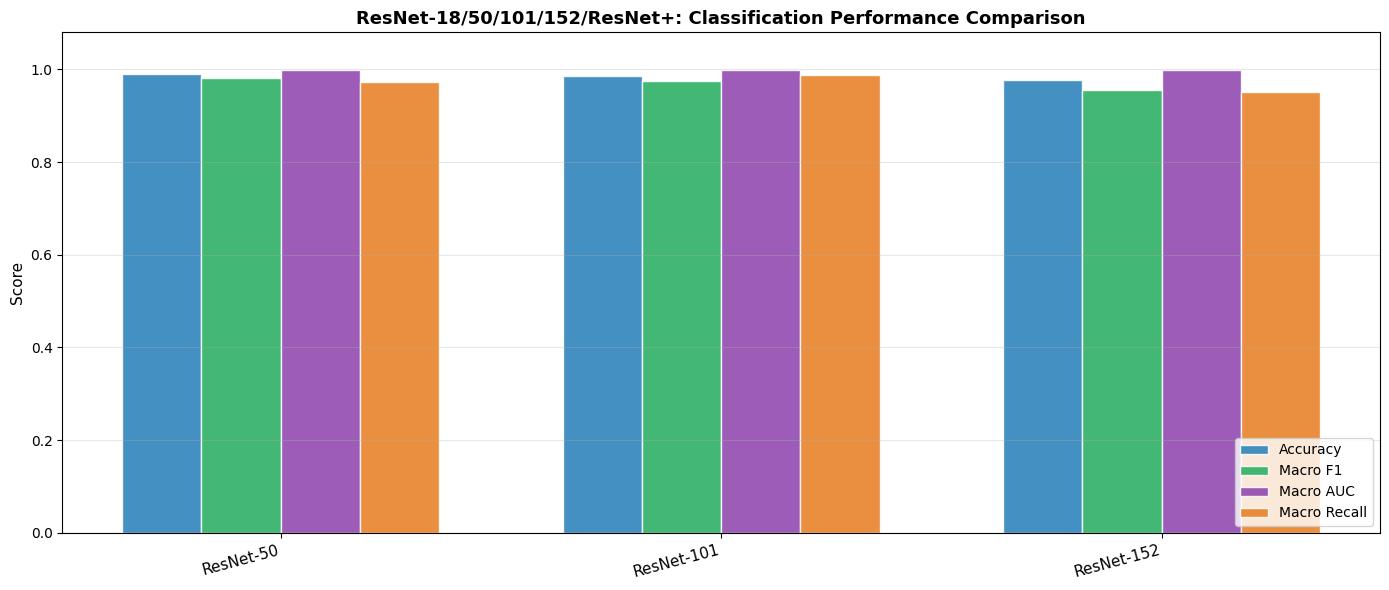

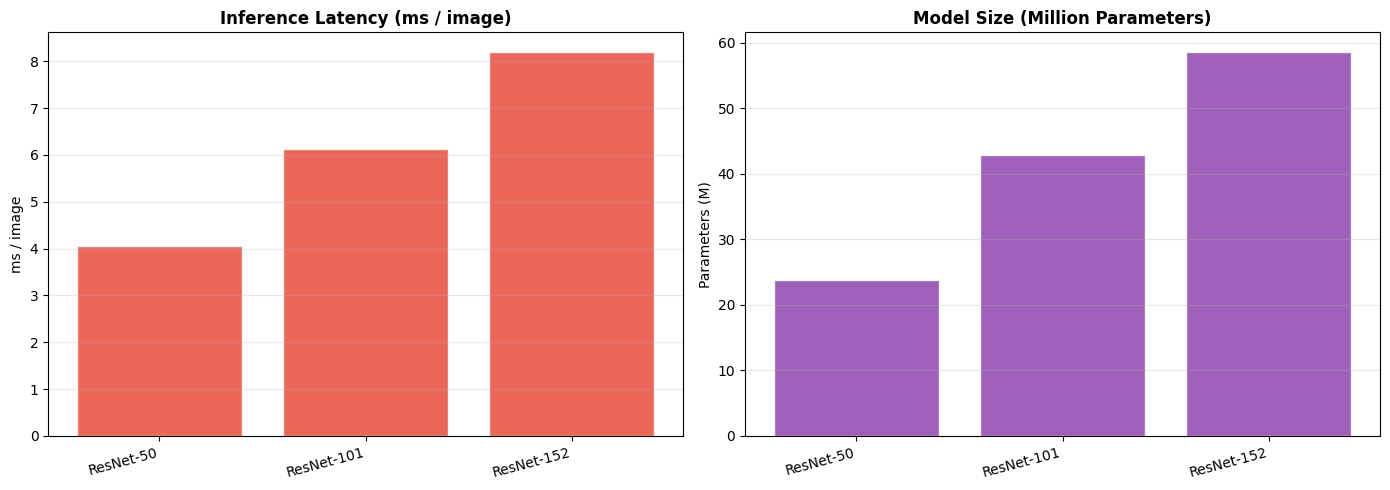

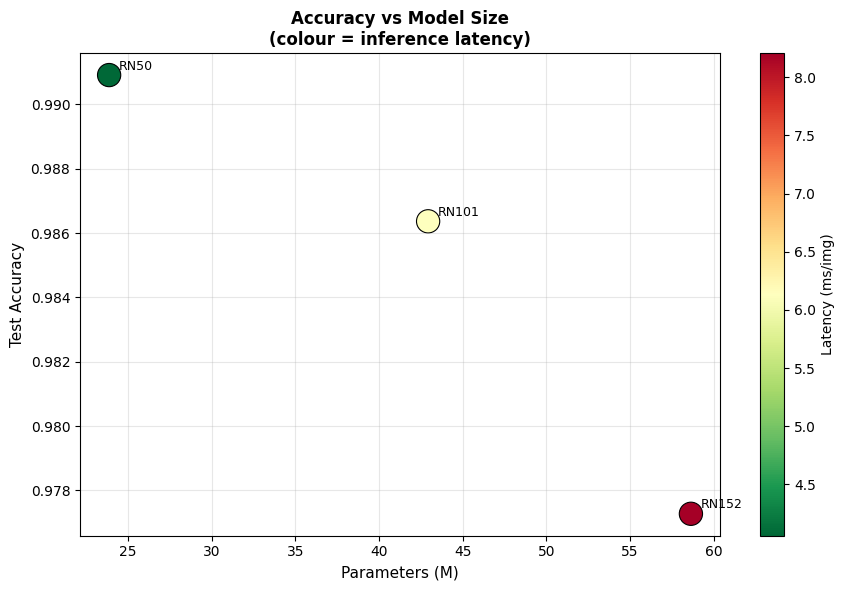

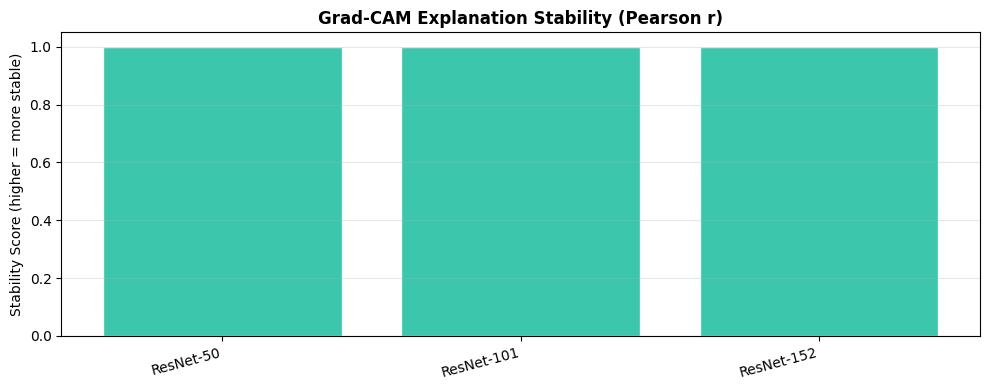

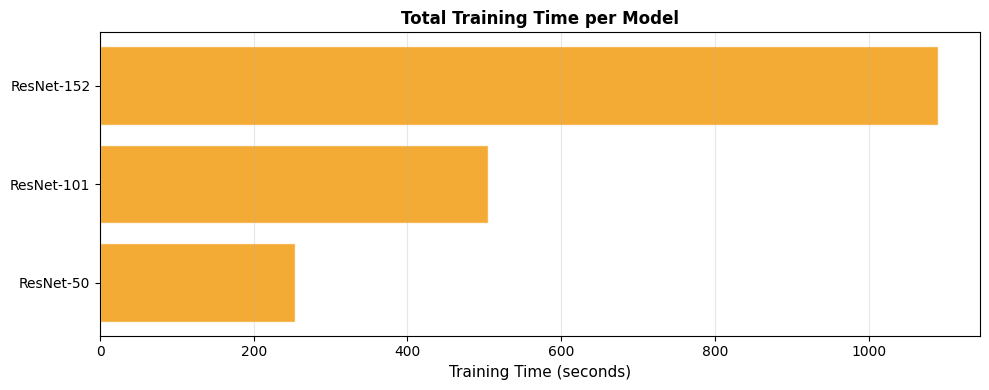

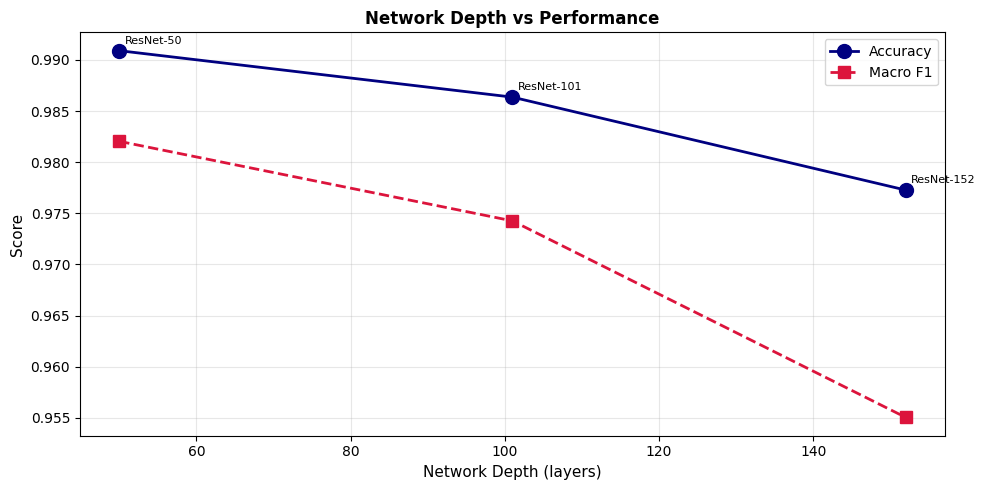

In [15]:
# ==========================================
# CELL 16: COMPARISON CHARTS
# ==========================================

model_names = df['Model'].tolist()
x     = np.arange(len(model_names))
bar_w = 0.18
palette = ['#2980b9', '#27ae60', '#8e44ad', '#e67e22']

# ---- Chart 1: Accuracy / F1 / AUC / Recall ----
fig, ax = plt.subplots(figsize=(14, 6))
metrics = [('accuracy','Accuracy'), ('macro_f1','Macro F1'),
           ('macro_auc','Macro AUC'), ('macro_rec','Macro Recall')]
for j, (col, label) in enumerate(metrics):
    ax.bar(x + j*bar_w, df[col], bar_w, label=label,
           color=palette[j], alpha=0.87, edgecolor='white')
ax.set_xticks(x + bar_w*1.5)
ax.set_xticklabels(model_names, rotation=15, ha='right', fontsize=11)
ax.set_ylim(0, 1.08)
ax.set_ylabel('Score', fontsize=11)
ax.set_title('ResNet-18/50/101/152/ResNet+: Classification Performance Comparison',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 2: Latency vs Parameters ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(model_names, df['latency_ms'], color='#e74c3c', alpha=0.85, edgecolor='white')
axes[0].set_title('Inference Latency (ms / image)', fontweight='bold')
axes[0].set_ylabel('ms / image')
axes[0].set_xticklabels(model_names, rotation=15, ha='right')
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(model_names, df['params_M'], color='#8e44ad', alpha=0.85, edgecolor='white')
axes[1].set_title('Model Size (Million Parameters)', fontweight='bold')
axes[1].set_ylabel('Parameters (M)')
axes[1].set_xticklabels(model_names, rotation=15, ha='right')
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 3: Accuracy vs Model Size (efficiency frontier) ----
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(df['params_M'], df['accuracy'],
                c=df['latency_ms'], cmap='RdYlGn_r',
                s=280, edgecolors='black', linewidths=0.8)
for _, row in df.iterrows():
    label = row['Model'].replace('ResNet-', 'RN').replace('ResNet+', 'RN+')
    ax.annotate(label, (row['params_M'], row['accuracy']),
                textcoords='offset points', xytext=(7, 4), fontsize=9)
plt.colorbar(sc, ax=ax, label='Latency (ms/img)')
ax.set_xlabel('Parameters (M)', fontsize=11)
ax.set_ylabel('Test Accuracy', fontsize=11)
ax.set_title('Accuracy vs Model Size\n(colour = inference latency)', fontweight='bold')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---- Chart 4: Grad-CAM Stability ----
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(model_names, df['stability'], color='#1abc9c', alpha=0.85, edgecolor='white')
ax.set_ylim(0, 1.05)
ax.set_title('Grad-CAM Explanation Stability (Pearson r)', fontweight='bold')
ax.set_ylabel('Stability Score (higher = more stable)')
ax.set_xticklabels(model_names, rotation=15, ha='right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 5: Training time ----
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(model_names, df['train_time_s'], color='#f39c12', alpha=0.85, edgecolor='white')
ax.set_xlabel('Training Time (seconds)', fontsize=11)
ax.set_title('Total Training Time per Model', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 6: Depth vs Accuracy line plot ----
depth_map = {'ResNet-18': 18, 'ResNet-50': 50,
             'ResNet-101': 101, 'ResNet-152': 152, 'ResNet+': 55}  # ResNet+ ~50+SE+CBAM
depths = [depth_map.get(m, 0) for m in model_names]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, df['accuracy'].tolist(), 'o-', color='navy', lw=2, ms=10, label='Accuracy')
ax.plot(depths, df['macro_f1'].tolist(), 's--', color='crimson', lw=2, ms=8, label='Macro F1')
for d, acc, name in zip(depths, df['accuracy'].tolist(), model_names):
    ax.annotate(name, (d, acc), textcoords='offset points', xytext=(4, 5), fontsize=8)
ax.set_xlabel('Network Depth (layers)', fontsize=11)
ax.set_ylabel('Score', fontsize=11)
ax.set_title('Network Depth vs Performance', fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [16]:
# ==========================================
# CELL 17: FINAL RANKING & RECOMMENDATION
# ==========================================

df['norm_latency']   = (df['latency_ms'] - df['latency_ms'].min()) / \
                       (df['latency_ms'].max() - df['latency_ms'].min() + 1e-9)
df['norm_stability'] = (df['stability']  - df['stability'].min())  / \
                       (df['stability'].max()  - df['stability'].min()  + 1e-9)

# Composite = 35% Accuracy + 25% F1 + 20% AUC + 10% Speed + 10% Stability
df['composite'] = (
    0.35 * df['accuracy']            +
    0.25 * df['macro_f1']            +
    0.20 * df['macro_auc']           +
    0.10 * (1 - df['norm_latency'])  +
    0.10 * df['norm_stability']
).round(4)

df_rank = df[['Model','accuracy','macro_f1','macro_auc',
              'latency_ms','params_M','stability','composite']]\
            .sort_values('composite', ascending=False).reset_index(drop=True)
df_rank.index += 1
df_rank.index.name = 'Rank'

print("\n" + "="*90)
print("  FINAL RANKING — ResNet-18 / ResNet-50 / ResNet-101 / ResNet-152 / ResNet+")
print("  IQ-OTH/NCCD Lung Cancer Detection")
print("="*90)
print(df_rank.round(4).to_string())
print("\nComposite = 35% Accuracy + 25% F1 + 20% AUC + 10% Speed + 10% Stability")

winner = df_rank.iloc[0]
print("\n" + "-"*90)
print(f"  RECOMMENDED MODEL : {winner['Model']}")
print(f"  Accuracy  : {winner['accuracy']:.4f}")
print(f"  Macro F1  : {winner['macro_f1']:.4f}")
print(f"  Macro AUC : {winner['macro_auc']:.4f}")
print(f"  Latency   : {winner['latency_ms']:.2f} ms/image")
print(f"  Stability : {winner['stability']:.4f}")
print("-"*90)


  FINAL RANKING — ResNet-18 / ResNet-50 / ResNet-101 / ResNet-152 / ResNet+
  IQ-OTH/NCCD Lung Cancer Detection
           Model  accuracy  macro_f1  macro_auc  latency_ms  params_M  stability  composite
Rank                                                                                       
1      ResNet-50    0.9909    0.9820     0.9988      4.0577     23.86        1.0     0.9805
2     ResNet-152    0.9773    0.9550     0.9988      8.2083     58.64        1.0     0.8805
3     ResNet-101    0.9864    0.9743     0.9995      6.1281     42.93        1.0     0.8388

Composite = 35% Accuracy + 25% F1 + 20% AUC + 10% Speed + 10% Stability

------------------------------------------------------------------------------------------
  RECOMMENDED MODEL : ResNet-50
  Accuracy  : 0.9909
  Macro F1  : 0.9820
  Macro AUC : 0.9988
  Latency   : 4.06 ms/image
  Stability : 1.0000
------------------------------------------------------------------------------------------


In [17]:
# ==========================================
# CELL 18: SAVE RESULTS TO GOOGLE DRIVE
# ==========================================
save_path = '/content/drive/My Drive/Kaggle/IQ-OTH-NCCD/resnet_18_50_101_152_plus_results.csv'
df_rank.to_csv(save_path)
print(f"Results saved to: {save_path}")

Results saved to: /content/drive/My Drive/Kaggle/IQ-OTH-NCCD/resnet_18_50_101_152_plus_results.csv
